# Week 4 — Product Performance Analysis

## Objective
Evaluate product-level sales, revenue, profitability, demand, and contribution to overall business performance.

## Goals
- Measure product sales performance.
- Identify top and low-performing products.
- Analyze product revenue contribution.
- Analyze units sold and purchase frequency.
- Evaluate estimated gross profit and margin.
- Identify fast-moving and slow-moving products.
- Perform Pareto / ABC analysis.
- Generate product-level business insights.

In [1]:
import pandas as pd
import numpy as np

sales_analysis = pd.read_csv(
    "analysis_ready_data/sales_analysis.csv"
)

sales_analysis.shape

(130402, 41)

In [2]:
sales_analysis["order_date"] = pd.to_datetime(
    sales_analysis["order_date"],
    errors="coerce"
)

sales_analysis["delivery_date"] = pd.to_datetime(
    sales_analysis["delivery_date"],
    errors="coerce"
)

In [3]:
print("Rows:", len(sales_analysis))
print("Columns:", sales_analysis.shape[1])

sales_analysis[
    [
        "so_id",
        "product_id",
        "product_name",
        "quantity",
        "line_total",
        "gross_profit",
        "order_status"
    ]
].head()

Rows: 130402
Columns: 41


,so_id,product_id,product_name,quantity,line_total,gross_profit,order_status
0,SO-990591,P018,Wheel Rim WR-24,19,214700,58900,Delivered
1,SO-990591,P026,Grease Cartridge GC-5,2,620,260,Delivered
2,SO-990591,P026,Grease Cartridge GC-5,3,930,390,Delivered
3,SO-990591,P013,Seal Kit SK-15,9,13050,4500,Delivered
4,SO-990591,P004,Track Chain TC-45,3,119400,21900,Delivered


In [4]:
delivered_sales = sales_analysis[
    sales_analysis["order_status"] == "Delivered"
].copy()

In [5]:
print("All sales line rows:", len(sales_analysis))
print("Delivered sales line rows:", len(delivered_sales))
print("Cancelled sales line rows:", len(sales_analysis) - len(delivered_sales))

All sales line rows: 130402
Delivered sales line rows: 117656
Cancelled sales line rows: 12746


In [6]:
delivered_sales["product_id"].nunique()

30

In [7]:
product_performance = (
    delivered_sales
    .groupby(
        [
            "product_id",
            "product_name",
            "category",
            "machine_type",
            "brand",
            "criticality_level",
            "usage_frequency"
        ]
    )
    .agg(
        total_units_sold=("quantity", "sum"),
        total_revenue=("line_total", "sum"),
        estimated_total_cost=("estimated_cost", "sum"),
        total_gross_profit=("gross_profit", "sum"),
        order_count=("so_id", "nunique"),
        customer_count=("customer_id", "nunique")
    )
    .reset_index()
)

In [8]:
product_performance["average_revenue_per_order"] = (
    product_performance["total_revenue"]
    / product_performance["order_count"]
)

product_performance["gross_margin_percent"] = (
    product_performance["total_gross_profit"]
    / product_performance["total_revenue"]
    * 100
)

product_performance["average_units_per_order"] = (
    product_performance["total_units_sold"]
    / product_performance["order_count"]
)

In [9]:
print("Unique products:", product_performance["product_id"].nunique())
print("Product summary rows:", len(product_performance))

product_performance.shape

Unique products: 30
Product summary rows: 30


(30, 16)

In [10]:
print(
    "Delivered sales revenue:",
    round(delivered_sales["line_total"].sum(), 2)
)

print(
    "Product summary revenue:",
    round(product_performance["total_revenue"].sum(), 2)
)

print(
    "Difference:",
    round(
        delivered_sales["line_total"].sum()
        - product_performance["total_revenue"].sum(),
        2
    )
)

Delivered sales revenue: 22958987430
Product summary revenue: 22958987430
Difference: 0


In [11]:
product_performance[
    [
        "product_id",
        "product_name",
        "category",
        "total_units_sold",
        "total_revenue",
        "total_gross_profit",
        "gross_margin_percent",
        "order_count",
        "customer_count"
    ]
].sort_values(
    "total_revenue",
    ascending=False
).head(10)

,product_id,product_name,category,total_units_sold,total_revenue,total_gross_profit,gross_margin_percent,order_count,customer_count
14,P015,Engine Block EB-600,Engine,40815,4856985000,959152500,19.747899,3411,499
13,P014,Transmission Assembly TA-800,Transmission,40574,3387929000,608610000,17.964072,3462,500
20,P021,Boom Cylinder BC-400,Hydraulic,41864,1934116800,443758400,22.943723,3481,500
18,P019,Swing Motor SWM-350,Hydraulic,41543,1653411400,357269800,21.608040,3476,499
3,P004,Track Chain TC-45,Undercarriage,40891,1627461800,298504300,18.341709,3392,500
9,P010,Turbocharger TB-900,Engine,42292,1475990800,253752000,17.191977,3542,500
10,P011,Hydraulic Cylinder HC-200,Hydraulic,42093,1161766800,256767300,22.101449,3595,500
0,P001,Hydraulic Pump HP-300,Hydraulic,41304,1011948000,229237200,22.653061,3499,499
29,P030,Fuel Pump FP-350,Engine,41595,910930500,228772500,25.114155,3509,500
21,P022,Control Valve CV-75,Hydraulic,41297,697919300,169317700,24.260355,3493,500


In [12]:
top_revenue_products = product_performance[
    [
        "product_id",
        "product_name",
        "total_revenue"
    ]
].sort_values(
    "total_revenue",
    ascending=False
).head(10)

top_revenue_products

,product_id,product_name,total_revenue
14,P015,Engine Block EB-600,4856985000
13,P014,Transmission Assembly TA-800,3387929000
20,P021,Boom Cylinder BC-400,1934116800
18,P019,Swing Motor SWM-350,1653411400
3,P004,Track Chain TC-45,1627461800
9,P010,Turbocharger TB-900,1475990800
10,P011,Hydraulic Cylinder HC-200,1161766800
0,P001,Hydraulic Pump HP-300,1011948000
29,P030,Fuel Pump FP-350,910930500
21,P022,Control Valve CV-75,697919300


In [13]:
top_units_products = product_performance[
    [
        "product_id",
        "product_name",
        "total_units_sold"
    ]
].sort_values(
    "total_units_sold",
    ascending=False
).head(10)

top_units_products

,product_id,product_name,total_units_sold
28,P029,Pressure Sensor PS-90,42702
9,P010,Turbocharger TB-900,42292
6,P007,Hydraulic Hose HH-60,42156
10,P011,Hydraulic Cylinder HC-200,42093
20,P021,Boom Cylinder BC-400,41864
5,P006,Alternator ALT-500,41843
15,P016,Radiator RD-250,41770
2,P003,Air Filter AF-120,41712
29,P030,Fuel Pump FP-350,41595
11,P012,Brake Pad BP-40,41549


In [14]:
top_profit_products = product_performance[
    [
        "product_id",
        "product_name",
        "total_gross_profit"
    ]
].sort_values(
    "total_gross_profit",
    ascending=False
).head(10)

top_profit_products

,product_id,product_name,total_gross_profit
14,P015,Engine Block EB-600,959152500
13,P014,Transmission Assembly TA-800,608610000
20,P021,Boom Cylinder BC-400,443758400
18,P019,Swing Motor SWM-350,357269800
3,P004,Track Chain TC-45,298504300
10,P011,Hydraulic Cylinder HC-200,256767300
9,P010,Turbocharger TB-900,253752000
0,P001,Hydraulic Pump HP-300,229237200
29,P030,Fuel Pump FP-350,228772500
21,P022,Control Valve CV-75,169317700


In [15]:
total_revenue = product_performance["total_revenue"].sum()

product_performance["revenue_contribution_percent"] = (
    product_performance["total_revenue"]
    / total_revenue
    * 100
)

In [16]:
product_performance[
    [
        "product_id",
        "product_name",
        "total_revenue",
        "revenue_contribution_percent"
    ]
].sort_values(
    "total_revenue",
    ascending=False
).head(10)

,product_id,product_name,total_revenue,revenue_contribution_percent
14,P015,Engine Block EB-600,4856985000,21.155049
13,P014,Transmission Assembly TA-800,3387929000,14.756439
20,P021,Boom Cylinder BC-400,1934116800,8.424225
18,P019,Swing Motor SWM-350,1653411400,7.201587
3,P004,Track Chain TC-45,1627461800,7.088561
9,P010,Turbocharger TB-900,1475990800,6.428815
10,P011,Hydraulic Cylinder HC-200,1161766800,5.060183
0,P001,Hydraulic Pump HP-300,1011948000,4.407633
29,P030,Fuel Pump FP-350,910930500,3.967642
21,P022,Control Valve CV-75,697919300,3.039852


In [17]:
product_performance = product_performance.sort_values(
    "total_revenue",
    ascending=False
).reset_index(drop=True)

In [18]:
product_performance["cumulative_revenue"] = (
    product_performance["total_revenue"].cumsum()
)

product_performance["cumulative_revenue_percent"] = (
    product_performance["cumulative_revenue"]
    / product_performance["total_revenue"].sum()
    * 100
)

In [19]:
product_performance["abc_class"] = np.select(
    [
        product_performance["cumulative_revenue_percent"] <= 80,
        product_performance["cumulative_revenue_percent"] <= 95
    ],
    [
        "A",
        "B"
    ],
    default="C"
)

In [20]:
product_performance["abc_class"].value_counts()

abc_class
C    14
A     9
B     7
Name: count, dtype: int64

In [21]:
product_performance[
    [
        "product_id",
        "product_name",
        "total_revenue",
        "revenue_contribution_percent",
        "cumulative_revenue_percent",
        "abc_class"
    ]
]

,product_id,product_name,total_revenue,revenue_contribution_percent,cumulative_revenue_percent,abc_class
0,P015,Engine Block EB-600,4856985000,21.155049,21.155049,A
1,P014,Transmission Assembly TA-800,3387929000,14.756439,35.911488,A
2,P021,Boom Cylinder BC-400,1934116800,8.424225,44.335713,A
3,P019,Swing Motor SWM-350,1653411400,7.201587,51.537300,A
4,P004,Track Chain TC-45,1627461800,7.088561,58.625861,A
5,P010,Turbocharger TB-900,1475990800,6.428815,65.054676,A
6,P011,Hydraulic Cylinder HC-200,1161766800,5.060183,70.114859,A
7,P001,Hydraulic Pump HP-300,1011948000,4.407633,74.522492,A
8,P030,Fuel Pump FP-350,910930500,3.967642,78.490134,A
9,P022,Control Valve CV-75,697919300,3.039852,81.529987,B


### ABC / Pareto Product Classification

Products were ranked by delivered sales revenue and classified using cumulative revenue contribution.

- Class A: 9 products
- Class B: 7 products
- Class C: 14 products

Class A products account for approximately the first 80% of cumulative revenue and represent the most commercially important products.

Class B products contribute the next portion of cumulative revenue up to approximately 95%.

Class C products contribute the remaining share of revenue.

This classification will later help prioritize inventory control, supplier management, and product-level decision making.

In [22]:
product_performance[
    [
        "product_id",
        "product_name",
        "total_units_sold",
        "order_count"
    ]
][["total_units_sold", "order_count"]].describe()

,total_units_sold,order_count
count,30.000000,30.000000
mean,41164.633333,3480.600000
std,723.742738,51.656425
min,39486.000000,3392.000000
25%,40767.750000,3452.500000
50%,41075.000000,3479.000000
75%,41682.750000,3515.000000
max,42702.000000,3595.000000


In [23]:
product_performance["units_percentile"] = (
    product_performance["total_units_sold"]
    .rank(pct=True)
)

product_performance["order_frequency_percentile"] = (
    product_performance["order_count"]
    .rank(pct=True)
)

product_performance["movement_score"] = (
    product_performance["units_percentile"]
    + product_performance["order_frequency_percentile"]
) / 2

In [24]:
q25 = product_performance["movement_score"].quantile(0.25)
q75 = product_performance["movement_score"].quantile(0.75)

product_performance["movement_class"] = np.select(
    [
        product_performance["movement_score"] >= q75,
        product_performance["movement_score"] <= q25
    ],
    [
        "Fast Moving",
        "Slow Moving"
    ],
    default="Medium Moving"
)

In [25]:
product_performance["movement_class"].value_counts()

movement_class
Medium Moving    14
Slow Moving       8
Fast Moving       8
Name: count, dtype: int64

In [26]:
product_performance[
    [
        "product_id",
        "product_name",
        "total_units_sold",
        "order_count",
        "movement_score",
        "movement_class"
    ]
].sort_values(
    "movement_score",
    ascending=False
)

,product_id,product_name,total_units_sold,order_count,movement_score,movement_class
6,P011,Hydraulic Cylinder HC-200,42093,3595,0.950000,Fast Moving
5,P010,Turbocharger TB-900,42292,3542,0.933333,Fast Moving
21,P007,Hydraulic Hose HH-60,42156,3534,0.883333,Fast Moving
14,P016,Radiator RD-250,41770,3544,0.866667,Fast Moving
23,P003,Air Filter AF-120,41712,3554,0.866667,Fast Moving
12,P006,Alternator ALT-500,41843,3539,0.850000,Fast Moving
18,P029,Pressure Sensor PS-90,42702,3506,0.850000,Fast Moving
19,P012,Brake Pad BP-40,41549,3517,0.733333,Fast Moving
8,P030,Fuel Pump FP-350,41595,3509,0.733333,Medium Moving
2,P021,Boom Cylinder BC-400,41864,3481,0.716667,Medium Moving


### Product Movement Classification

Product movement was evaluated using both total units sold and order frequency.

Because the differences between products are relatively small, the classifications represent relative performance within this dataset rather than absolute fast- or slow-moving behavior.

A percentile-based movement score was created from units sold and order frequency.

- Top quartile: Fast Moving
- Middle 50%: Medium Moving
- Bottom quartile: Slow Moving

This approach avoids using arbitrary fixed thresholds and reflects the actual distribution of product demand.

In [31]:
abc_movement_table = pd.crosstab(
    product_performance["abc_class"],
    product_performance["movement_class"]
)

abc_movement_table

movement_class,Fast Moving,Medium Moving,Slow Moving
abc_class,,,
A,2,5,2
B,2,2,3
C,4,7,3


In [28]:
product_performance["product_strategy"] = (
    product_performance["abc_class"]
    + " - "
    + product_performance["movement_class"]
)

In [35]:
product_performance.sort_values(
    ["abc_class", "movement_score"],
    ascending=[True, False]
)[
    [
        "product_id",
        "product_name",
        "abc_class",
        "movement_class",
        "product_strategy",
        "total_revenue",
        "total_units_sold",
        "gross_margin_percent"
    ]
]

,product_id,product_name,abc_class,movement_class,product_strategy,total_revenue,total_units_sold,gross_margin_percent
6,P011,Hydraulic Cylinder HC-200,A,Fast Moving,A - Fast Moving,1161766800,42093,22.101449
5,P010,Turbocharger TB-900,A,Fast Moving,A - Fast Moving,1475990800,42292,17.191977
8,P030,Fuel Pump FP-350,A,Medium Moving,A - Medium Moving,910930500,41595,25.114155
2,P021,Boom Cylinder BC-400,A,Medium Moving,A - Medium Moving,1934116800,41864,22.943723
7,P001,Hydraulic Pump HP-300,A,Medium Moving,A - Medium Moving,1011948000,41304,22.653061
3,P019,Swing Motor SWM-350,A,Medium Moving,A - Medium Moving,1653411400,41543,21.608040
1,P014,Transmission Assembly TA-800,A,Medium Moving,A - Medium Moving,3387929000,40574,17.964072
0,P015,Engine Block EB-600,A,Slow Moving,A - Slow Moving,4856985000,40815,19.747899
4,P004,Track Chain TC-45,A,Slow Moving,A - Slow Moving,1627461800,40891,18.341709
14,P016,Radiator RD-250,B,Fast Moving,B - Fast Moving,426054000,41770,23.529412


In [36]:
abc_movement_table

movement_class,Fast Moving,Medium Moving,Slow Moving
abc_class,,,
A,2,5,2
B,2,2,3
C,4,7,3


### ABC Class vs Product Movement

ABC classification and product movement measure different aspects of product performance.

- ABC classification reflects revenue contribution.
- Movement classification reflects relative sales volume and order frequency.

The cross-tab shows that not all Class A products are fast-moving. Some high-revenue products have only medium or slow movement, likely because higher-value products can generate substantial revenue without being purchased as frequently.

Likewise, some Class C products are fast-moving but contribute less revenue, suggesting lower unit values.

This distinction is important for inventory and product strategy because high-revenue and high-movement products may require different management approaches.

In [37]:
def assign_product_priority(row):
    if row["abc_class"] == "A" and row["movement_class"] == "Fast Moving":
        return "Critical Priority"
    elif row["abc_class"] == "A":
        return "High Value"
    elif row["movement_class"] == "Fast Moving":
        return "High Movement"
    elif row["abc_class"] == "B":
        return "Medium Priority"
    else:
        return "Standard Priority"

product_performance["priority_group"] = product_performance.apply(
    assign_product_priority,
    axis=1
)

In [38]:
product_performance["priority_group"].value_counts()

priority_group
Standard Priority    10
High Value            7
High Movement         6
Medium Priority       5
Critical Priority     2
Name: count, dtype: int64

In [39]:
top_margin_products = product_performance[
    [
        "product_id",
        "product_name",
        "total_revenue",
        "total_gross_profit",
        "gross_margin_percent",
        "abc_class",
        "movement_class"
    ]
].sort_values(
    "gross_margin_percent",
    ascending=False
).head(10)

top_margin_products

,product_id,product_name,total_revenue,total_gross_profit,gross_margin_percent,abc_class,movement_class
28,P027,O-Ring Set OR-50,19617600,8991400,45.833333,C,Medium Moving
29,P026,Grease Cartridge GC-5,12526170,5252910,41.935484,C,Slow Moving
26,P008,Bucket Tooth BT-10,23814220,9854160,41.379310,C,Medium Moving
27,P017,Fan Belt FB-30,21278400,8184000,38.461538,C,Medium Moving
25,P002,Engine Oil Filter OF-90,29460240,11047590,37.500000,C,Medium Moving
20,P028,Light Assembly LA-18,92907000,33033600,35.555556,C,Medium Moving
24,P020,Pivot Pin PP-12,47052250,16366000,34.782609,C,Medium Moving
22,P013,Seal Kit SK-15,57894150,19963500,34.482759,C,Slow Moving
23,P003,Air Filter AF-120,52140000,17936160,34.400000,C,Fast Moving
21,P007,Hydraulic Hose HH-60,61126200,19813320,32.413793,C,Fast Moving


In [40]:
lowest_margin_products = product_performance[
    [
        "product_id",
        "product_name",
        "total_revenue",
        "total_gross_profit",
        "gross_margin_percent",
        "abc_class",
        "movement_class"
    ]
].sort_values(
    "gross_margin_percent",
    ascending=True
).head(10)

lowest_margin_products

,product_id,product_name,total_revenue,total_gross_profit,gross_margin_percent,abc_class,movement_class
5,P010,Turbocharger TB-900,1475990800,253752000,17.191977,A,Fast Moving
1,P014,Transmission Assembly TA-800,3387929000,608610000,17.964072,A,Medium Moving
4,P004,Track Chain TC-45,1627461800,298504300,18.341709,A,Slow Moving
0,P015,Engine Block EB-600,4856985000,959152500,19.747899,A,Slow Moving
3,P019,Swing Motor SWM-350,1653411400,357269800,21.608040,A,Medium Moving
6,P011,Hydraulic Cylinder HC-200,1161766800,256767300,22.101449,A,Fast Moving
7,P001,Hydraulic Pump HP-300,1011948000,229237200,22.653061,A,Medium Moving
12,P006,Alternator ALT-500,468641600,106699650,22.767857,B,Fast Moving
2,P021,Boom Cylinder BC-400,1934116800,443758400,22.943723,A,Medium Moving
10,P009,Starter Motor SM-700,604150300,139887150,23.154362,B,Slow Moving


In [41]:
total_gross_profit = product_performance["total_gross_profit"].sum()

product_performance["profit_contribution_percent"] = (
    product_performance["total_gross_profit"]
    / total_gross_profit
    * 100
)

In [44]:
product_performance.sort_values(
    "total_gross_profit",
    ascending=False
)[
    [
        "product_id",
        "product_name",
        "revenue_contribution_percent",
        "profit_contribution_percent",
        "gross_margin_percent"
    ]
].head(10)

,product_id,product_name,revenue_contribution_percent,profit_contribution_percent,gross_margin_percent
0,P015,Engine Block EB-600,21.155049,19.376792,19.747899
1,P014,Transmission Assembly TA-800,14.756439,12.295135,17.964072
2,P021,Boom Cylinder BC-400,8.424225,8.964804,22.943723
3,P019,Swing Motor SWM-350,7.201587,7.217562,21.608040
4,P004,Track Chain TC-45,7.088561,6.030382,18.341709
6,P011,Hydraulic Cylinder HC-200,5.060183,5.187211,22.101449
5,P010,Turbocharger TB-900,6.428815,5.126296,17.191977
7,P001,Hydraulic Pump HP-300,4.407633,4.631048,22.653061
8,P030,Fuel Pump FP-350,3.967642,4.621660,25.114155
9,P022,Control Valve CV-75,3.039852,3.420555,24.260355


In [45]:
product_performance["gross_margin_percent"].describe()

count    30.000000
mean     28.436460
std       7.683556
min      17.191977
25%      22.811824
50%      26.982120
75%      34.462069
max      45.833333
Name: gross_margin_percent, dtype: float64

In [46]:
margin_q25 = product_performance["gross_margin_percent"].quantile(0.25)
margin_q75 = product_performance["gross_margin_percent"].quantile(0.75)

product_performance["profitability_class"] = np.select(
    [
        product_performance["gross_margin_percent"] >= margin_q75,
        product_performance["gross_margin_percent"] <= margin_q25
    ],
    [
        "High Margin",
        "Low Margin"
    ],
    default="Medium Margin"
)

In [47]:
product_performance["profitability_class"].value_counts()

profitability_class
Medium Margin    14
Low Margin        8
High Margin       8
Name: count, dtype: int64

In [48]:
product_performance[
    [
        "product_id",
        "product_name",
        "abc_class",
        "movement_class",
        "profitability_class",
        "priority_group",
        "total_revenue",
        "total_units_sold",
        "gross_margin_percent"
    ]
].sort_values(
    "total_revenue",
    ascending=False
)

,product_id,product_name,abc_class,movement_class,profitability_class,priority_group,total_revenue,total_units_sold,gross_margin_percent
0,P015,Engine Block EB-600,A,Slow Moving,Low Margin,High Value,4856985000,40815,19.747899
1,P014,Transmission Assembly TA-800,A,Medium Moving,Low Margin,High Value,3387929000,40574,17.964072
2,P021,Boom Cylinder BC-400,A,Medium Moving,Medium Margin,High Value,1934116800,41864,22.943723
3,P019,Swing Motor SWM-350,A,Medium Moving,Low Margin,High Value,1653411400,41543,21.608040
4,P004,Track Chain TC-45,A,Slow Moving,Low Margin,High Value,1627461800,40891,18.341709
5,P010,Turbocharger TB-900,A,Fast Moving,Low Margin,Critical Priority,1475990800,42292,17.191977
6,P011,Hydraulic Cylinder HC-200,A,Fast Moving,Low Margin,Critical Priority,1161766800,42093,22.101449
7,P001,Hydraulic Pump HP-300,A,Medium Moving,Low Margin,High Value,1011948000,41304,22.653061
8,P030,Fuel Pump FP-350,A,Medium Moving,Medium Margin,High Value,910930500,41595,25.114155
9,P022,Control Valve CV-75,B,Medium Moving,Medium Margin,Medium Priority,697919300,41297,24.260355


### Product Profitability Classification

Gross margin percentages vary across products from approximately 17% to 46%.

Products were therefore classified relative to the observed margin distribution:

- Top quartile: High Margin
- Middle 50%: Medium Margin
- Bottom quartile: Low Margin

This classification complements the ABC revenue classification and movement analysis. Revenue contribution, sales movement, and profitability represent different dimensions of product performance and should be evaluated together rather than independently.

In [49]:
category_performance = (
    delivered_sales
    .groupby("category")
    .agg(
        total_units_sold=("quantity", "sum"),
        total_revenue=("line_total", "sum"),
        total_gross_profit=("gross_profit", "sum"),
        order_count=("so_id", "nunique"),
        product_count=("product_id", "nunique")
    )
    .reset_index()
)

In [50]:
category_performance["gross_margin_percent"] = (
    category_performance["total_gross_profit"]
    / category_performance["total_revenue"]
    * 100
)

In [51]:
category_performance = category_performance.sort_values(
    "total_revenue",
    ascending=False
)

category_performance

,category,total_units_sold,total_revenue,total_gross_profit,order_count,product_count,gross_margin_percent
6,Engine,165182,7585962300,1526685000,10056,4,20.125133
8,Hydraulic,250257,6520288500,1476163720,12607,6,22.639546
13,Transmission,40574,3387929000,608610000,3462,1,17.964072
14,Undercarriage,161405,3016239400,690379900,9905,4,22.888763
5,Electrical,123682,1165698900,279620400,8339,3,23.987361
4,Cooling,41770,426054000,100248000,3544,1,23.529412
3,Cabin,41091,322564350,92454750,3480,1,28.662420
12,Sensors,42702,168672900,51242400,3506,1,30.379747
2,Brakes,41549,101795050,27006850,3517,1,26.530612
7,Filters,82629,81600240,28983750,6275,2,35.519197


In [52]:
category_performance["revenue_contribution_percent"] = (
    category_performance["total_revenue"]
    / category_performance["total_revenue"].sum()
    * 100
)

In [53]:
category_performance[
    [
        "category",
        "product_count",
        "total_units_sold",
        "total_revenue",
        "total_gross_profit",
        "gross_margin_percent",
        "revenue_contribution_percent"
    ]
]

,category,product_count,total_units_sold,total_revenue,total_gross_profit,gross_margin_percent,revenue_contribution_percent
6,Engine,4,165182,7585962300,1526685000,20.125133,33.041363
8,Hydraulic,6,250257,6520288500,1476163720,22.639546,28.399722
13,Transmission,1,40574,3387929000,608610000,17.964072,14.756439
14,Undercarriage,4,161405,3016239400,690379900,22.888763,13.137511
5,Electrical,3,123682,1165698900,279620400,23.987361,5.077310
4,Cooling,1,41770,426054000,100248000,23.529412,1.855718
3,Cabin,1,41091,322564350,92454750,28.662420,1.404959
12,Sensors,1,42702,168672900,51242400,30.379747,0.734670
2,Brakes,1,41549,101795050,27006850,26.530612,0.443378
7,Filters,2,82629,81600240,28983750,35.519197,0.355417


In [54]:
monthly_product_sales = (
    delivered_sales
    .groupby(
        [
            "product_id",
            "product_name",
            delivered_sales["order_date"].dt.to_period("M")
        ]
    )
    .agg(
        monthly_units_sold=("quantity", "sum"),
        monthly_revenue=("line_total", "sum")
    )
    .reset_index()
)

In [55]:
monthly_product_sales = monthly_product_sales.rename(
    columns={"order_date": "year_month"}
)

In [56]:
monthly_product_sales["year_month"] = (
    monthly_product_sales["year_month"].astype(str)
)

In [57]:
monthly_product_sales.head()

,product_id,product_name,year_month,monthly_units_sold,monthly_revenue
0,P001,Hydraulic Pump HP-300,2019-01,467,11441500
1,P001,Hydraulic Pump HP-300,2019-02,390,9555000
2,P001,Hydraulic Pump HP-300,2019-03,612,14994000
3,P001,Hydraulic Pump HP-300,2019-04,542,13279000
4,P001,Hydraulic Pump HP-300,2019-05,695,17027500


In [58]:
product_monthly_demand = (
    monthly_product_sales
    .groupby(
        ["product_id", "product_name"]
    )
    .agg(
        avg_monthly_units=("monthly_units_sold", "mean"),
        max_monthly_units=("monthly_units_sold", "max"),
        min_monthly_units=("monthly_units_sold", "min")
    )
    .reset_index()
)

In [59]:
product_performance = product_performance.merge(
    product_monthly_demand,
    on=["product_id", "product_name"],
    how="left",
    validate="one_to_one"
)

In [60]:
product_monthly_demand = (
    monthly_product_sales
    .groupby(["product_id", "product_name"])
    .agg(
        avg_monthly_units=("monthly_units_sold", "mean"),
        std_monthly_units=("monthly_units_sold", "std"),
        max_monthly_units=("monthly_units_sold", "max"),
        min_monthly_units=("monthly_units_sold", "min")
    )
    .reset_index()
)

In [61]:
product_monthly_demand["demand_cv"] = (
    product_monthly_demand["std_monthly_units"]
    / product_monthly_demand["avg_monthly_units"]
)

In [62]:
product_performance = product_performance.merge(
    product_monthly_demand[
        [
            "product_id",
            "std_monthly_units",
            "demand_cv"
        ]
    ],
    on="product_id",
    how="left",
    validate="one_to_one"
)

In [63]:
cv_q25 = product_performance["demand_cv"].quantile(0.25)
cv_q75 = product_performance["demand_cv"].quantile(0.75)

product_performance["demand_stability"] = np.select(
    [
        product_performance["demand_cv"] <= cv_q25,
        product_performance["demand_cv"] >= cv_q75
    ],
    [
        "Stable Demand",
        "Variable Demand"
    ],
    default="Moderate Demand"
)

In [64]:
product_performance["demand_stability"].value_counts()

demand_stability
Moderate Demand    14
Stable Demand       8
Variable Demand     8
Name: count, dtype: int64

### Monthly Demand Stability

Monthly product demand was analyzed using the coefficient of variation (CV), which compares the standard deviation of monthly units sold with average monthly demand.

- Lower CV values indicate relatively stable demand.
- Higher CV values indicate greater month-to-month variability.

Products were classified relative to the observed demand distribution into Stable, Moderate, and Variable demand groups.

This metric will later support inventory planning and demand forecasting.

In [65]:
import matplotlib.pyplot as plt

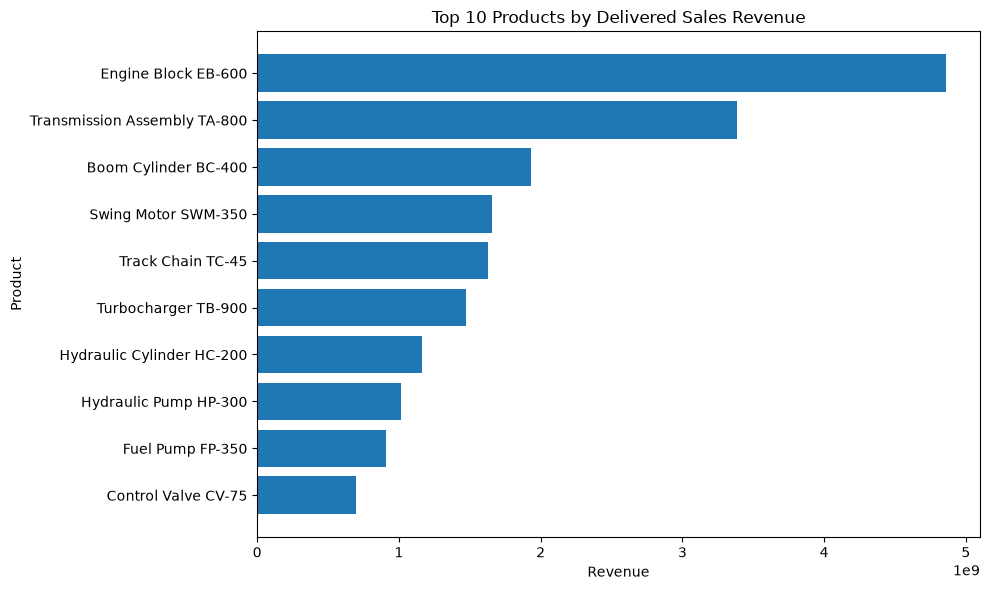

In [66]:
top10_revenue = (
    product_performance
    .sort_values("total_revenue", ascending=False)
    .head(10)
    .sort_values("total_revenue", ascending=True)
)

plt.figure(figsize=(10, 6))

plt.barh(
    top10_revenue["product_name"],
    top10_revenue["total_revenue"]
)

plt.title("Top 10 Products by Delivered Sales Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

### Top Products by Revenue

Product performance was evaluated using delivered sales only.

The revenue ranking highlights the products that make the largest contribution to realized sales. Revenue performance should not be interpreted alone, however, because high-revenue products may differ from high-volume or high-margin products.

For this reason, product revenue is evaluated together with movement, profitability, ABC classification, and demand stability.

In [67]:
pareto_products = (
    product_performance
    .sort_values("total_revenue", ascending=False)
    .reset_index(drop=True)
)

pareto_products["cumulative_revenue_percent"] = (
    pareto_products["total_revenue"].cumsum()
    / pareto_products["total_revenue"].sum()
    * 100
)

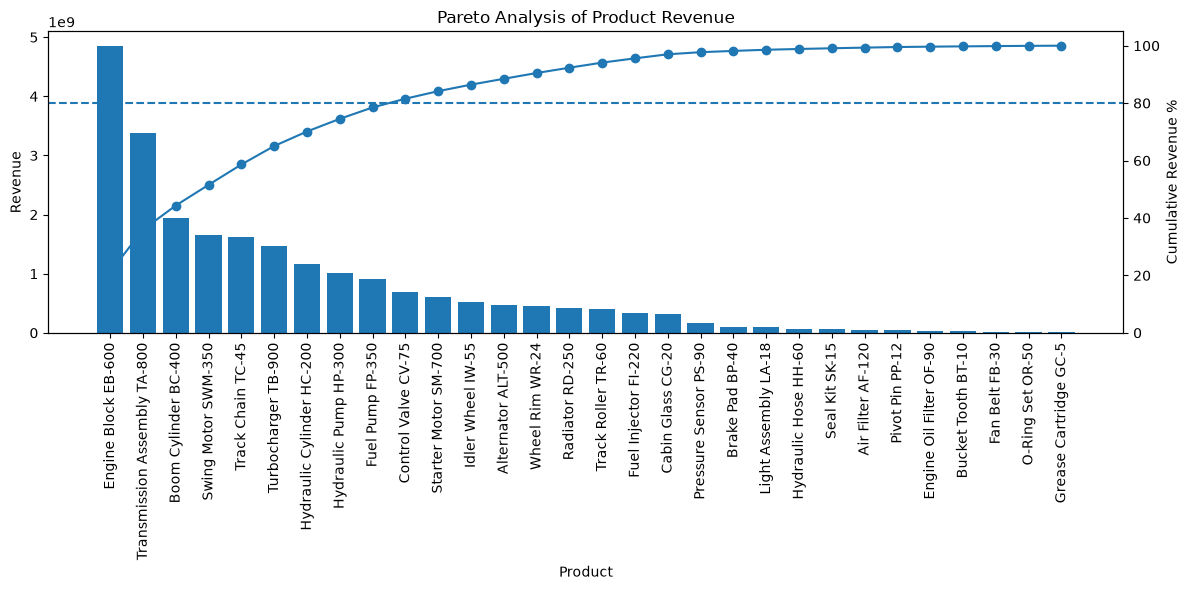

In [68]:
fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.bar(
    pareto_products["product_name"],
    pareto_products["total_revenue"]
)

ax1.set_xlabel("Product")
ax1.set_ylabel("Revenue")
ax1.tick_params(axis="x", rotation=90)

ax2 = ax1.twinx()

ax2.plot(
    pareto_products["product_name"],
    pareto_products["cumulative_revenue_percent"],
    marker="o"
)

ax2.axhline(
    80,
    linestyle="--"
)

ax2.set_ylabel("Cumulative Revenue %")
ax2.set_ylim(0, 105)

plt.title("Pareto Analysis of Product Revenue")

fig.tight_layout()
plt.show()

### Pareto Analysis

The Pareto chart combines individual product revenue with cumulative revenue contribution.

The analysis shows that a relatively small group of products generates the majority of delivered sales revenue.

Products contributing to approximately the first 80% of cumulative revenue were classified as Class A products.

This concentration suggests that a limited set of products has a disproportionately large influence on overall sales performance and therefore deserves greater attention in inventory planning, supplier management, and availability monitoring.

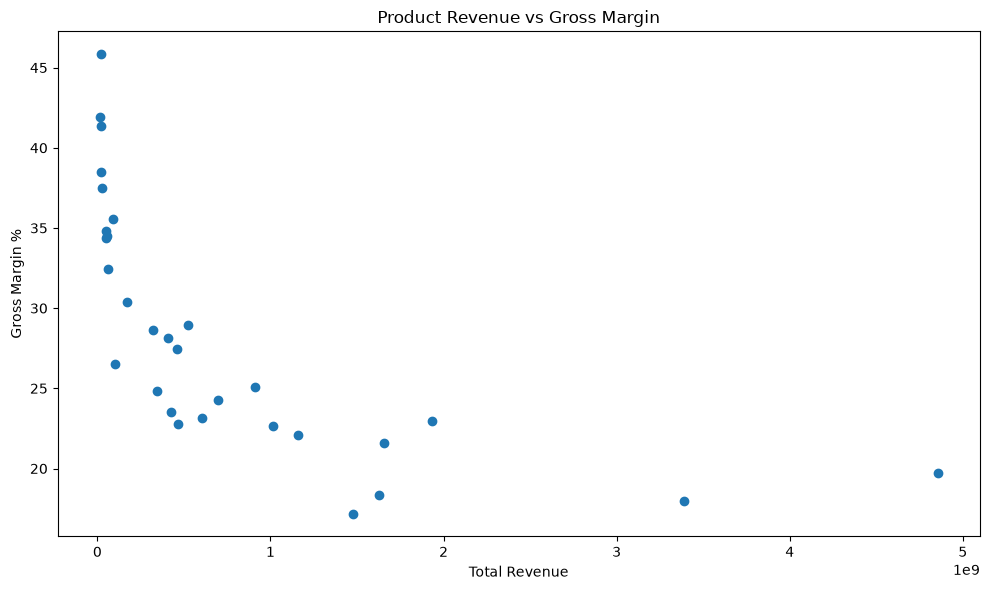

In [69]:
plt.figure(figsize=(10, 6))

plt.scatter(
    product_performance["total_revenue"],
    product_performance["gross_margin_percent"]
)

plt.xlabel("Total Revenue")
plt.ylabel("Gross Margin %")
plt.title("Product Revenue vs Gross Margin")

plt.tight_layout()
plt.show()

In [70]:
strategic_products = product_performance[
    [
        "product_id",
        "product_name",
        "abc_class",
        "movement_class",
        "profitability_class",
        "demand_stability",
        "priority_group",
        "total_revenue",
        "total_gross_profit",
        "gross_margin_percent"
    ]
].sort_values(
    ["abc_class", "total_revenue"],
    ascending=[True, False]
)

strategic_products.head(15)

,product_id,product_name,abc_class,movement_class,profitability_class,demand_stability,priority_group,total_revenue,total_gross_profit,gross_margin_percent
0,P015,Engine Block EB-600,A,Slow Moving,Low Margin,Stable Demand,High Value,4856985000,959152500,19.747899
1,P014,Transmission Assembly TA-800,A,Medium Moving,Low Margin,Moderate Demand,High Value,3387929000,608610000,17.964072
2,P021,Boom Cylinder BC-400,A,Medium Moving,Medium Margin,Variable Demand,High Value,1934116800,443758400,22.943723
3,P019,Swing Motor SWM-350,A,Medium Moving,Low Margin,Variable Demand,High Value,1653411400,357269800,21.608040
4,P004,Track Chain TC-45,A,Slow Moving,Low Margin,Moderate Demand,High Value,1627461800,298504300,18.341709
5,P010,Turbocharger TB-900,A,Fast Moving,Low Margin,Stable Demand,Critical Priority,1475990800,253752000,17.191977
6,P011,Hydraulic Cylinder HC-200,A,Fast Moving,Low Margin,Stable Demand,Critical Priority,1161766800,256767300,22.101449
7,P001,Hydraulic Pump HP-300,A,Medium Moving,Low Margin,Stable Demand,High Value,1011948000,229237200,22.653061
8,P030,Fuel Pump FP-350,A,Medium Moving,Medium Margin,Variable Demand,High Value,910930500,228772500,25.114155
9,P022,Control Valve CV-75,B,Medium Moving,Medium Margin,Moderate Demand,Medium Priority,697919300,169317700,24.260355


### Strategic Product View

Product performance was evaluated across multiple dimensions rather than using revenue alone.

The analysis combines:

- Revenue importance through ABC classification
- Product movement through sales volume and order frequency
- Profitability through gross margin
- Demand consistency through monthly demand stability
- Strategic priority through combined product characteristics

This multi-dimensional approach provides a more balanced view of product performance and avoids over-relying on a single KPI.

In [71]:
print("Product rows:", len(product_performance))
print("Unique products:", product_performance["product_id"].nunique())

print(
    "Total delivered revenue:",
    round(delivered_sales["line_total"].sum(), 2)
)

print(
    "Product performance revenue:",
    round(product_performance["total_revenue"].sum(), 2)
)

print(
    "Revenue difference:",
    round(
        delivered_sales["line_total"].sum()
        - product_performance["total_revenue"].sum(),
        2
    )
)

Product rows: 30
Unique products: 30
Total delivered revenue: 22958987430
Product performance revenue: 22958987430
Revenue difference: 0


In [72]:
import os

os.makedirs("week4_outputs", exist_ok=True)

product_performance.to_csv(
    "week4_outputs/product_performance.csv",
    index=False
)

category_performance.to_csv(
    "week4_outputs/category_performance.csv",
    index=False
)

monthly_product_sales.to_csv(
    "week4_outputs/monthly_product_sales.csv",
    index=False
)

strategic_products.to_csv(
    "week4_outputs/strategic_products.csv",
    index=False
)

print("Week 4 outputs exported successfully.")

Week 4 outputs exported successfully.


In [73]:
for file in os.listdir("week4_outputs"):
    print(file)

category_performance.csv
monthly_product_sales.csv
product_performance.csv
strategic_products.csv
